In [ ]:
# import paulssonlab.deaton.trenchripper.trenchripper as tr
# import trenchripper as tr
import trenchripper as tr

import warnings

warnings.filterwarnings(action="once")

import matplotlib

matplotlib.rcParams["figure.figsize"] = [20, 10]

import glob
import os
import shutil
import re
import pandas as pd
import h5py
import numpy as np
import skimage as sk
import matplotlib.pyplot as plt

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.0' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [2]:
# addition of active memory manager
import dask
dask.config.set({'distributed.scheduler.active-memory-manager.start': True});
dask.config.set({'distributed.scheduler.worker-ttl': "5m"});
dask.config.set({'distributed.scheduler.allowed-failures': 100});

dask_wd = "/home/lag36/scratch/lag36/dask"

### Define headpaths

In [2]:
headpath = "/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/Barcodes/"
hdf5inputpath = "/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run/"

### Function wrappers to parallelize

In [151]:
def parse_and_save_futures_results(futures_dict, function_name):
    """
    Parse the results of futures and save them to a DataFrame and a pickle file.
    Args:
        futures_dict (dict): Dictionary with indices as keys and futures as values.
        function_name (str): Name of the function used to generate the futures.
    Returns:
        pd.DataFrame: DataFrame containing the status, done, result, and exception of each future.
    """
    def parse_futures_dict_entry_to_row(future):
        """
        Parse a single future entry to a dictionary row.
        Args:
            future (dask.distributed.Future): Future object to parse.
        Returns:
            dict: Dictionary containing the status, done, result, and exception of the future.
        """
        try:
            result = future.result()
        except Exception as e:
            result = str(e)
        future_dict_row = {'status': future.status,
                    'done':future.done(),
                    'result': result,
                    'exception': str(future.exception()),
                    'key': future.key}
        return future_dict_row

    futures_dict_to_table = {index: parse_futures_dict_entry_to_row(future)
                          for index, future in futures_dict.items()}

    df_futures = (pd.DataFrame
                  .from_dict(futures_dict_to_table, orient='index')
                  .astype({'status': 'category',
                           'done': bool,
                           'result': 'object',
                           'exception': 'object'})
                  .reset_index()
                  .rename(columns={'index': 'index'})
                  .sort_values(by='index', ascending=True))

    df_futures.to_pickle(f"{headpath}/futures_{function_name}.pkl")

    return df_futures

def deploy_function_in_dask(function, 
                            indices,
                            *args,
                            **kwargs):
    """
    Deploy a function in Dask for each index in the list.
    Args:
        function (callable): Function to deploy.
        indices (list): List of indices to process.
        *args: Additional positional arguments for the function.
        **kwargs: Additional keyword arguments for the function.
    Returns:
        dict: Dictionary with indices as keys and futures as values.
    """
    futures_dict = {}
    for index in indices:
        future = dask_controller.daskclient.submit(function,
                                               index, # Notice how it is formatted: index is relative to headpath
                                               *args,
                                               **kwargs)
        futures_dict[index] = future
    df_futures = parse_and_save_futures_results(futures_dict, function.__name__)
    return df_futures

### Create image files for the new channel

In [3]:
def group_filenames_per_fov(headpath, pattern="*BF_*"):
    """
    Groups filenames in the specified directory by their FOV number.
    Args:
        headpath (str): The directory path where the files are located.
        pattern (str): The pattern to match filenames. Default is "*BF_*".
    Returns:
        dict: A sorted dictionary where keys are FOV numbers and values are lists of filenames.
    """
    filenames = glob.glob(headpath + pattern)
    filenames_per_fov = {}
    fov_pattern = re.compile(r"fov=(\d+)")

    for filename in filenames:
        match = fov_pattern.search(os.path.basename(filename))
        if match:
            fov_number = int(match.group(1))
            if fov_number not in filenames_per_fov:
                filenames_per_fov[fov_number] = []
            filenames_per_fov[fov_number].append(filename)
    # Also sort keys
    filenames_per_fov = dict(sorted(filenames_per_fov.items()))
    sorted_filenames_per_fov = {}
    # Sort filenames
    for fov_number, filenames in filenames_per_fov.items():
        sorted_filenames = sorted(filenames, key=lambda x: int(re.search(r'_t=(\d+)', x).group(1)))
        sorted_filenames_per_fov[fov_number] = sorted_filenames
    return sorted_filenames_per_fov

def copy_all_files_per_fov(filename_list_single_fov: list,
                           pattern_to_replace="BF",
                           pattern_to_replace_with="BFSmoothed"):
    for i, filename in enumerate(filename_list_single_fov):
        new_filename = filename.replace(pattern_to_replace, pattern_to_replace_with)
        print(new_filename)
        shutil.copy(filename, new_filename)
    return 0

def copy_all_files_all_fovs(filenames_per_fov):
    futures_list = []
    for fov, filename_list_single_fov in filenames_per_fov.items():
        future = dask_controller.daskclient.submit(copy_all_files_per_fov, filename_list_single_fov)
        futures_list.append(future)
    results = dask_controller.daskclient.gather(futures_list)
    return 0

### Add entry to metadata

In [24]:
def add_fake_channel_to_metadata(df_metadata, config_template='BF', config_new='BFSmoothed'):
    """
    Adds a new configuration to the metadata DataFrame for BF smoothed data.
    Args:
        df_metadata (pd.DataFrame): The original metadata DataFrame.
        config_template (str): The configuration to use as a template for the new config.
        config_new (str): The name of the new configuration to be added.
    Returns:
        pd.DataFrame: The updated metadata DataFrame with the new configuration added.
    """
    df_subset_new = (\
        df_metadata
        .loc[df_metadata['config'] == config_template, :]
        .assign(config=config_new)
    )
    return (pd
            .concat([df_metadata, df_subset_new], ignore_index=True)
            .sort_values(by=['fov', 't', 'config'], ignore_index=True)
    )

def add_fake_channel_to_all_metadata_files(metadata_filenames, config_template='BF', config_new='BFSmoothed'):
    """
    Adds a new configuration to all metadata files in the specified list.
    Args:
        metadata_filenames (list): List of metadata file paths.
    Returns:
        None
    """
    for metadata_filename in metadata_filenames:
        df_metadata = pd.read_hdf(metadata_filename)
        df_metadata = add_fake_channel_to_metadata(df_metadata, config_template, config_new)
        df_metadata.to_hdf(metadata_filename, key='data', mode='w')
    return 0

In [25]:
metadata_files = glob.glob(hdf5inputpath + '*metadata*')
pd.read_hdf('/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run/metadata_9.hdf5')
metadata_files

['/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run/metadata_1.hdf5',
 '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run/metadata_10.hdf5',
 '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run/metadata_2.hdf5',
 '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run/metadata_3.hdf5',
 '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run/metadata_4.hdf5',
 '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run/metadata_5.hdf5',
 '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run/metadata_6.hdf5',
 '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run/metadata_7.hdf5',
 '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run/metadata_8.hdf5',
 '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run/metadata_9.hdf5']

### Smooth BFSmoothed channel

In [17]:
# filenames_per_fov_BFSmoothed = group_filenames_per_fov(hdf5inputpath, pattern="*BFSmoothed_*")
# filenames_per_fov_BFSmoothed
filenames_per_fov_BF

def smooth_all_images_per_fov(filename_list_single_fov_origin,
                              sigma = 15,
                              pattern_origin = 'BF_',
                              pattern_destination = 'BFSmoothed_'
                              ):
    
    for i, filename_origin in enumerate(filename_list_single_fov):
        with h5py.File(filename_origin, 'r') as f:
            image = f['data'][:]

        smoothed_image = sk_util.img_as_uint(sk.filters.gaussian(image, sigma=sigma))
        filename_destination = filename.replace(pattern_origin, pattern_destination)

        with h5py.File(filename_destination, 'a') as f_out:
            if 'data' in f_out:
                del f_out['data']
            f_out.create_dataset("data", data=smoothed_image_uint16, chunks=(128, 128), dtype='uint16')
            
    return 0

# def smooth_all_images_per_fov(filename_list_single_fov, sigma = 15):
#     for i, file in enumerate(filename_list_single_fov):
#         with h5py.File(file, 'r+') as f:
#             image = f['data'][:]
#             smoothed_data = sk.util.img_as_uint(sk.filters.gaussian(image, sigma=sigma))
#             if "data" in f.keys():
#                 del f['data']
#             f['data'] = smoothed_data

def smooth_all_images_all_fovs(filenames_per_fov):
    futures_list = []
    for fov_number, filename_list_single_fov in filenames_per_fov.items():
        future = dask_controller.daskclient.submit(smooth_all_images_per_fov, filename_list_single_fov)
        futures_list.append(future)
    results = dask_controller.daskclient.gather(futures_list)
    return 0

### Viewer

In [19]:
with h5py.File(filenames_per_fov_BF[0][9], 'r') as f:
    image = f['data'][:]
    # plt.imshow(image, cmap='gray')

# with h5py.File(filtered_files[100], 'r') as f:
#     image_2 = f['data'][:]
#     # plt.imshow(image_2, cmap='gray')

Text(0.5, 1.0, 'Image from file 5000')

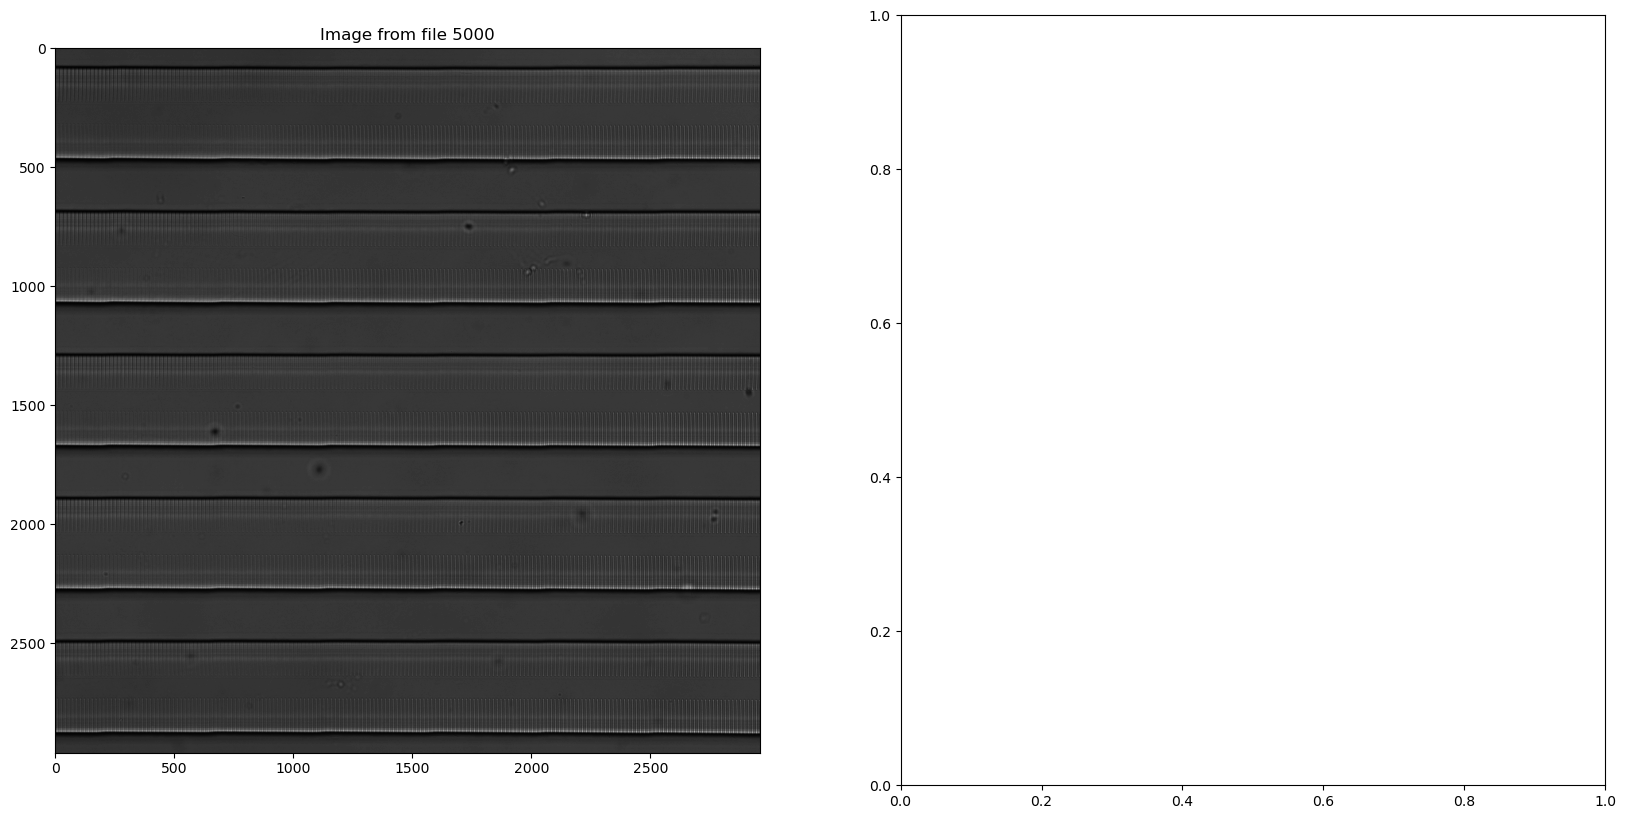

In [20]:
fig, axs = plt.subplots(1, 2, figsize=(20, 10))
axs[0].imshow(image, cmap='gray')
axs[0].set_title('Image from file 5000')
# axs[1].imshow(image_2, cmap='gray')
# axs[1].set_title('Image from file 0')

### Record drift

In [7]:
filenames_per_fov_BF = group_filenames_per_fov(hdf5inputpath, pattern="*BF_*")
filenames_per_fov = filenames_per_fov_BF
filenames_per_fov

# Get only the first 10 fovs for testing
# filenames_per_fov_reduced = {fov: filenames_per_fov[fov] for fov in list(filenames_per_fov.keys())[:10]}
# filenames_per_fov_reduced

{0: ['/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run/fov=0_config=BF_t=1.hdf5',
  '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run/fov=0_config=BF_t=2.hdf5',
  '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run/fov=0_config=BF_t=3.hdf5',
  '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run/fov=0_config=BF_t=4.hdf5',
  '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run/fov=0_config=BF_t=5.hdf5',
  '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run/fov=0_config=BF_t=6.hdf5',
  '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run/fov=0_config=BF_t=7.hdf5',
  '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run/fov=0_config=BF_t=8.hdf5',
  '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run/fov=0_config=BF_t=9.hdf5',
  '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run/fov=0_config=BF_t=10.hdf5'],
 1: ['/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-

In [4]:
def register_shift_coordinates_single_fov(fov_number: int, filenames_per_fov):
    filename_list_single_fov = filenames_per_fov[fov_number]
    n_timepoints = len(filename_list_single_fov)
    shift_coords = np.zeros((n_timepoints, 2), dtype=float)
    
    for i in range(1, len(filename_list_single_fov)):
        with h5py.File(filename_list_single_fov[i-1], 'r') as f:
            img_previous = f['data'][:]
        with h5py.File(filename_list_single_fov[i], 'r') as f:
            img_current = f['data'][:]
        
        shift, _, _ = sk.registration.phase_cross_correlation(img_previous,
                                                              img_current,
                                                              normalization=None)
        shift_coords[i, :] = shift
    
    return shift_coords

In [ ]:
indices = list(filenames_per_fov.keys())

In [46]:
dask_wd = "/home/lag36/scratch/lag36/dask"
dask_controller = tr.trcluster.dask_controller(
    walltime="0:30:00",
    local=False,
    n_workers=200,
    n_workers_min=20,
    memory="2GB",
    working_directory=dask_wd,
)
dask_controller.startdask()
dask_controller.displaydashboard()

20m
0:30:00


In [47]:
df_futures = deploy_function_in_dask(register_shift_coordinates_single_fov, 
                            indices,
                            filenames_per_fov)

### Fix position with incorrect drift

In [121]:
def find_bad_drift_timepoints(shift_coords_x, max_allowed_shift=MAX_ALLOWED_SHIFT_PIXELS):
    """
    Find timepoints with bad drift based on x shift coordinates.
    Args:
        shift_coords_x (np.ndarray): Array of x shift coordinates.
        max_allowed_shift (int): Maximum allowed shift in pixels.
    Returns:
        np.ndarray: Indices of timepoints with bad drift.
    """
    return np.where(np.abs(shift_coords_x) > max_allowed_shift)[0]

def get_closest_fov_with_correct_drift(fov_number, df_futures, bad_drift_index, max_allowed_shift=MAX_ALLOWED_SHIFT_PIXELS):
    """
    Get the closest FOV with correct drift.
    Args:
        fov_number (int): Current FOV number.
        df_futures (pd.DataFrame): DataFrame containing shift coordinates.
        bad_drift_index (int): Index of the bad drift timepoint.
        max_allowed_shift (int): Maximum allowed shift in pixels.
    Returns:
        int: Closest FOV number with correct drift.
    """
    found_closest_correct_fov = False
    fov_number_closest_lower = fov_number - 1
    fov_number_closest_upper = fov_number + 1
    fov_number_closest_correct = None
    shift_coords_closest_correct = None
    
    while not found_closest_correct_fov:
        if fov_number_closest_lower in df_futures.index:
            if not df_futures.loc[fov_number_closest_lower, 'is_wrong_x_shift'][bad_drift_index]:
                fov_number_closest_correct = fov_number_closest_lower
                shift_coords_closest_correct = df_futures.loc[fov_number_closest_lower, 'shift_coords'][bad_drift_index, 1]
                found_closest_correct_fov = True

        if fov_number_closest_upper in df_futures.index:
            if not df_futures.loc[fov_number_closest_upper, 'is_wrong_x_shift'][bad_drift_index]:
                fov_number_closest_correct = fov_number_closest_upper
                shift_coords_closest_upper = df_futures.loc[fov_number_closest_upper, 'shift_coords'][bad_drift_index,1]
                shift_coords_closest_correct = shift_coords_closest_upper
                found_closest_correct_fov = True

        fov_number_closest_lower -= 1
        fov_number_closest_upper += 1

    return fov_number_closest_correct, shift_coords_closest_correct
    
def get_closest_fovs_with_correct_drifts(fov_number, df_futures, bad_drift_indices, max_allowed_shift=MAX_ALLOWED_SHIFT_PIXELS):
    """
    Get the closest FOVs with correct drift for all bad drift indices.
    Args:
        fov_number (int): Current FOV number.
        df_futures (pd.DataFrame): DataFrame containing shift coordinates.
        bad_drift_indices (np.ndarray): Indices of bad drift timepoints.
        max_allowed_shift (int): Maximum allowed shift in pixels.
    Returns:
        list: List of tuples containing FOV number and shift coordinates for each bad drift index.
    """
    closest_fovs = []
    for bad_drift_index in bad_drift_indices:
        closest_fov, shift_coords = get_closest_fov_with_correct_drift(fov_number, df_futures, bad_drift_index, max_allowed_shift)
        closest_fovs.append((closest_fov, shift_coords))
    return closest_fovs
    
def correct_shift_coordinates(shift_coords, bad_drift_indices, shift_coords_to_replace):
    """
    Correct shift coordinates for bad drift indices.
    Args:
        shift_coords (np.ndarray): Original shift coordinates.
        bad_drift_indices (np.ndarray): Indices of bad drift timepoints.
        shift_coords_to_replace (np.ndarray): Shift coordinates to replace with.
    Returns:
        np.ndarray: Corrected shift coordinates.
    """
    corrected_shift_coords = np.copy(shift_coords)
    for i, bad_index in enumerate(bad_drift_indices):
        corrected_shift_coords[bad_index, 1] = shift_coords_to_replace[i]
    return corrected_shift_coords
corrected_shift_coords = correct_shift_coordinates(row['shift_coords'], row['bad_drift_timepoints'], [x[1] for x in row['closest_correct_fovs']])

In [122]:
# shifts_all_fovs = np.stack(df_futures['shift_coords'].values)
# print('shifts counts in y:')
# print(np.unique(shifts_all_fovs[:,:,0], return_counts=True))
# print('shifts counts in x:')
# print(np.unique(shifts_all_fovs[:,:,1], return_counts=True))

In [123]:
MAX_ALLOWED_SHIFT_PIXELS = 5

df_futures = pd.read_pickle(f"{headpath}/futures_register_shift_coordinates_single_fov.pkl")
df_futures = \
(
    df_futures
    [['result']]
    .rename(columns={'result': 'shift_coords'})
    .assign(is_wrong_x_shift = lambda df_: df_['shift_coords']
            .apply(lambda x: np.abs(x[:, 1]) > MAX_ALLOWED_SHIFT_PIXELS))
    .assign(has_wrong_x_shift = lambda df_: df_['is_wrong_x_shift']
            .apply(lambda x: np.any(x)))
)

# Apply corrections
df_futures_with_wrong_shifts = \
(
    df_futures[df_futures['has_wrong_x_shift']]
    .assign(bad_drift_timepoints = lambda df_: df_.apply(
        lambda row: find_bad_drift_timepoints(row['shift_coords'][:, 1]), axis=1))
    .assign(closest_correct_fovs = lambda df_: df_.apply(
        lambda row: get_closest_fovs_with_correct_drifts(row.name, df_futures, row['bad_drift_timepoints']), axis=1))
    .assign(shift_coords_corrected = lambda df_: df_.apply(
        lambda row: correct_shift_coordinates(row['shift_coords'], row['bad_drift_timepoints'], [x[1] for x in row['closest_correct_fovs']]), axis=1))
)

# Merge corrections and apply cumulative drift
df_futures = \
(
    df_futures
    .assign(shift_coords_corrected = lambda df_: np.where(
        ~df_['has_wrong_x_shift'],
        df_['shift_coords'],
        np.nan))
    .assign(shift_coords_corrected = lambda df_: df_['shift_coords_corrected'].combine_first(
        df_futures_with_wrong_shifts['shift_coords_corrected']))
    .merge(df_futures_with_wrong_shifts.loc[:, ['bad_drift_timepoints', 'closest_correct_fovs']],
           left_index=True, right_index=True, how='left')
    .assign(cumulative_shift_coords = lambda df_: df_['shift_coords_corrected'].apply(
        lambda x: np.cumsum(x, axis=0)))
)

assert df_futures['shift_coords_corrected'].isna().sum() == 0

In [125]:
df_futures.to_pickle(f"{headpath}/futures_register_shift_coordinates_single_fov_corrected.pkl")

### Apply the drift to images

In [ ]:
df_drift = pd.read_pickle(f"{headpath}/futures_register_shift_coordinates_single_fov_corrected.pkl")
N_TIMEPOINTS = 10

In [ ]:
def group_filenames_per_fov_time(headpath, pattern="*fov*", n_timepoints= 10):
    """
    Groups filenames in the specified directory by their FOV number and timepoint.
    Args:
        headpath (str): The directory path where the files are located.
        pattern (str): The pattern to match filenames. Default is "*fov*".
    Returns:
        dict: A sorted dictionary of dictionaries where the key of the outer dict is the fov number and the key of the inner dict is the timepoint.
    """
    filenames_per_fov_all_channels = group_filenames_per_fov(headpath, pattern=pattern)
    filenames_per_fov_all_channels_time = {}
    for fov, filenames in filenames_per_fov_all_channels.items():
        filenames_per_fov_all_channels_time[fov] = {timepoint: [] for timepoint in range(1, n_timepoints+1)}
        for filename in filenames:
            timepoint = int(re.search(r'_t=(\d+)', filename).group(1))
            filenames_per_fov_all_channels_time[fov][timepoint].append(filename)

    assert len(filenames_per_fov_all_channels_time) == len(filenames_per_fov_all_channels)
    assert np.all((np.array([len(filenames_per_fov_all_channels_time[fov]) for fov in filenames_per_fov_all_channels_time]) == N_TIMEPOINTS))
    return filenames_per_fov_all_channels_time

def correct_drift_single_image(image, cumulative_shift_coords_t):
    shift_y, shift_x = cumulative_shift_coords_t
    transform = sk.transform.AffineTransform(translation=(-shift_x, -shift_y))
    image_corrected = sk.transform.warp(image,
                                        transform,
                                        mode='constant',
                                        preserve_range=True,
                                        cval=np.median(image)).astype(image.dtype)
    return image_corrected

def correct_drift_single_fov_single_timepoint(
    fov: int,
    timepoint: int,
    filenames_per_fov_all_channels_all_timepoints: dict,
    cumulative_shift_coords_t: np.ndarray, # (y, x) coordinates for each timepoint
):
    """
    Correct drift for a single FOV and timepoint.
    Args:
        fov (int): FOV number.
        timepoint (int): Timepoint number.
        filenames_per_fov_all_channels_time (dict): Dictionary of filenames grouped by FOV and timepoint.
        df_drift (pd.DataFrame): DataFrame containing drift information.
        headpath (str): Path to the directory containing the files.
    Returns:
        None
    """
    filenames_fov_single_timepoint_all_channels = filenames_per_fov_all_channels_all_timepoints[fov][timepoint]
    
    for filename in filenames_fov_single_timepoint_all_channels:
        filename_drift_corrected = filename.replace("/run/", "/run_drift_corrected/")
        print(filename)
        with h5py.File(filename, 'r') as f:
            image = f['data'][:]
        image_corrected = correct_drift_single_image(image, cumulative_shift_coords_t)
        with h5py.File(filename_drift_corrected, 'w') as f_out:
            f_out.create_dataset("data", data=image_corrected, chunks=(128, 128), dtype='uint16')
    
    return 0
    
def correct_drift_single_fov_all_timepoints(
        fov: int,
        filenames_per_fov_all_channels_all_timepoints: dict):
    
    cumulative_shift_coords = df_drift.loc[fov, 'cumulative_shift_coords']
    for timepoint in range(1, N_TIMEPOINTS + 1):
        correct_drift_single_fov_single_timepoint(
            fov=fov,
            timepoint=timepoint,
            filenames_per_fov_all_channels_all_timepoints=filenames_per_fov_all_channels_all_timepoints,
            cumulative_shift_coords_t=cumulative_shift_coords[timepoint - 1]
        )
    return 0

In [ ]:
filenames_per_fov_all_channels_all_timepoints = group_filenames_per_fov_time(hdf5inputpath, pattern="*fov*", n_timepoints=N_TIMEPOINTS)
indices = list(df_drift.index)
assert indices == [i for i in range(len(indices))]

In [186]:
dask_wd = "/home/lag36/scratch/lag36/dask"
dask_controller = tr.trcluster.dask_controller(
    walltime="0:30:00",
    local=False,
    n_workers=200,
    n_workers_min=20,
    memory="2GB",
    working_directory=dask_wd,
)
dask_controller.startdask()
dask_controller.displaydashboard()

20m
0:30:00


In [187]:
df_futures_correct_drift_single_fov_all_timepoints = deploy_function_in_dask(
    correct_drift_single_fov_all_timepoints,
    indices,
    filenames_per_fov_all_channels_all_timepoints
)

#### Done with applying drift!

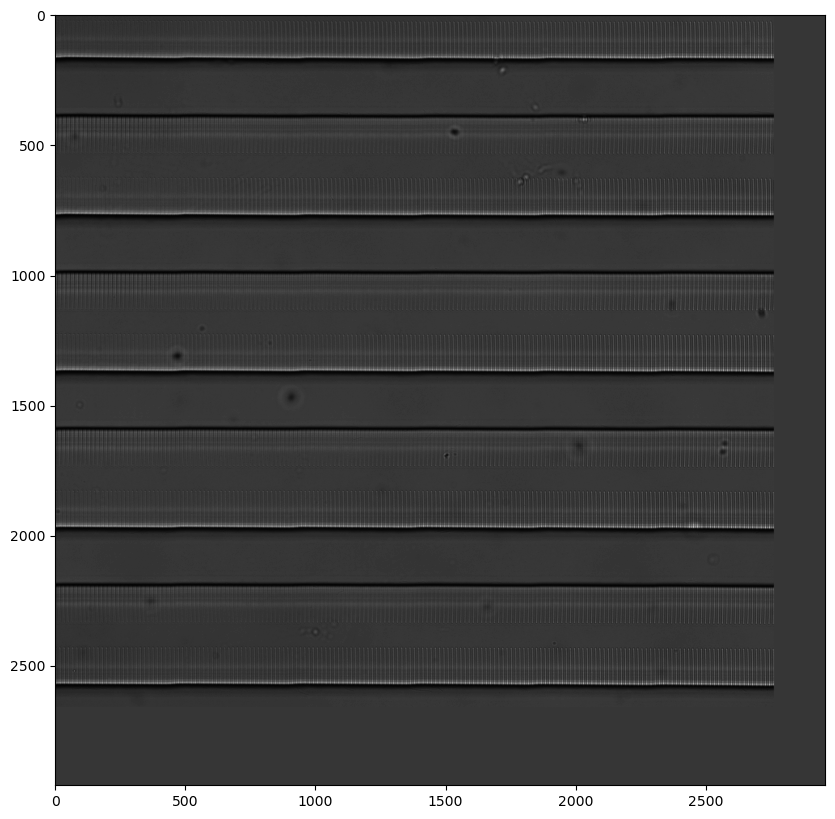

In [139]:
with h5py.File(filenames_per_fov_all_channels_all_timepoints[fov][4][0].replace("/run/", "/run_drift_corrected/"), 'r') as f:
    image_corrected = f['data'][:]
    # print(image_corrected.shape)
    plt.imshow(image_corrected, cmap='gray')

In [74]:
hdf5inputpath = "/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run/"
hdf5_drift_corrected_path = "/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/run_drift_corrected/"

### Viewer to check drift

In [58]:
import ipywidgets as widgets
from IPython.display import display, clear_output

def show_preview_single_timepoint(
    filenames_per_fov_single_channels_single_time: list,
):
    """
    Show a preview of images for a single FOV and timepoint.
    Args:
        filenames_per_fov_all_channels_time (dict): Dictionary of filenames grouped by FOV and timepoint.
    Returns:
        None
    """
    plt.close('all')
    fig, axs = plt.subplots(1, 4, figsize=(20, 10))

    TOP_LEFT_X = 1200
    TOP_LEFT_Y = 900
    WIDTH = 200
    HEIGHT = 200

    lookup_limits = [[0,10000], [1000,10000], [500,2000], [500, 3000]]

    for i, filename in enumerate(filenames_per_fov_single_channels_single_time):
        with h5py.File(filename, 'r') as f:
            # image = f['data'][TOP_LEFT:TOP_LEFT+HEIGHT, TOP_LEFT:TOP_LEFT+WIDTH]
            image = f['data'][:]
        axs[i].imshow(image, cmap='gray', vmin = lookup_limits[i][0], vmax = lookup_limits[i][1])
        axs[i].set_xlim(TOP_LEFT_X, TOP_LEFT_X + WIDTH)
        axs[i].set_ylim(TOP_LEFT_Y + HEIGHT, TOP_LEFT_Y)
        # axs[i].set_title(f"FOV {fov}, Timepoint {timepoint}, Channel {i+1}")
        axs[i].axis('off')
    plt.tight_layout()
    plt.show()
    # plt.close()


import ipywidgets as widgets
from IPython.display import display, clear_output
fov = 0
def interactive_time_slider(filenames_per_fov_all_channels_time):
    """
    Create an interactive slider to select timepoint and view image previews.
    Args:
        filenames_by_timepoint (dict): Dictionary where keys are timepoints (int)
                                       and values are lists of filenames for each channel.
    Returns:
        None
    """
    def update(timepoint):
        clear_output(wait=True)
        display(slider)
        show_preview_single_timepoint(filenames_per_fov_all_channels_time[fov][timepoint])

    slider = widgets.IntSlider(value=1, min=1, max=10, step=1, description='Timepoint:')
    slider.observe(lambda change: update(change['new']), names='value')
    display(slider)
    update(slider.value)  # initial display
    # widgets.interact(update, timepoint=slider)

IntSlider(value=10, description='Timepoint:', max=10, min=1)

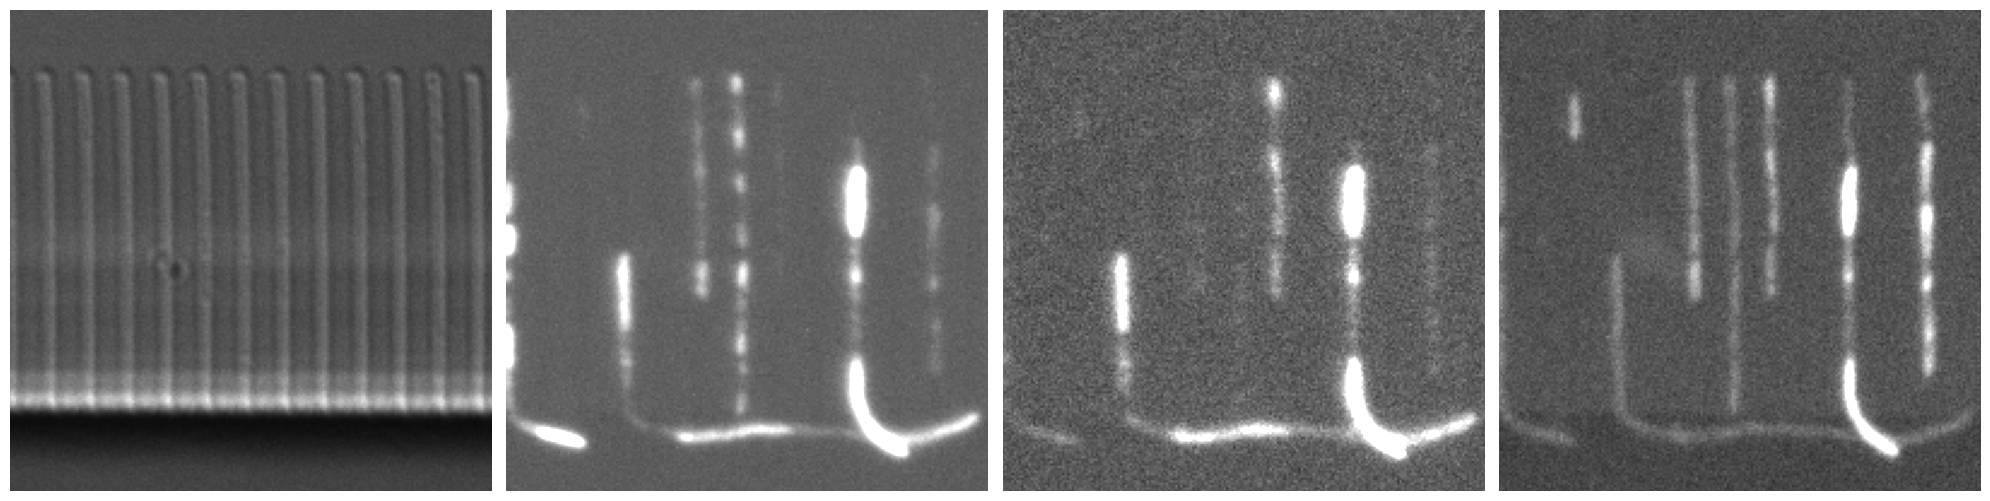

In [68]:
interactive_time_slider(filenames_per_fov_all_channels_time)

IntSlider(value=10, description='Timepoint:', max=10, min=1)

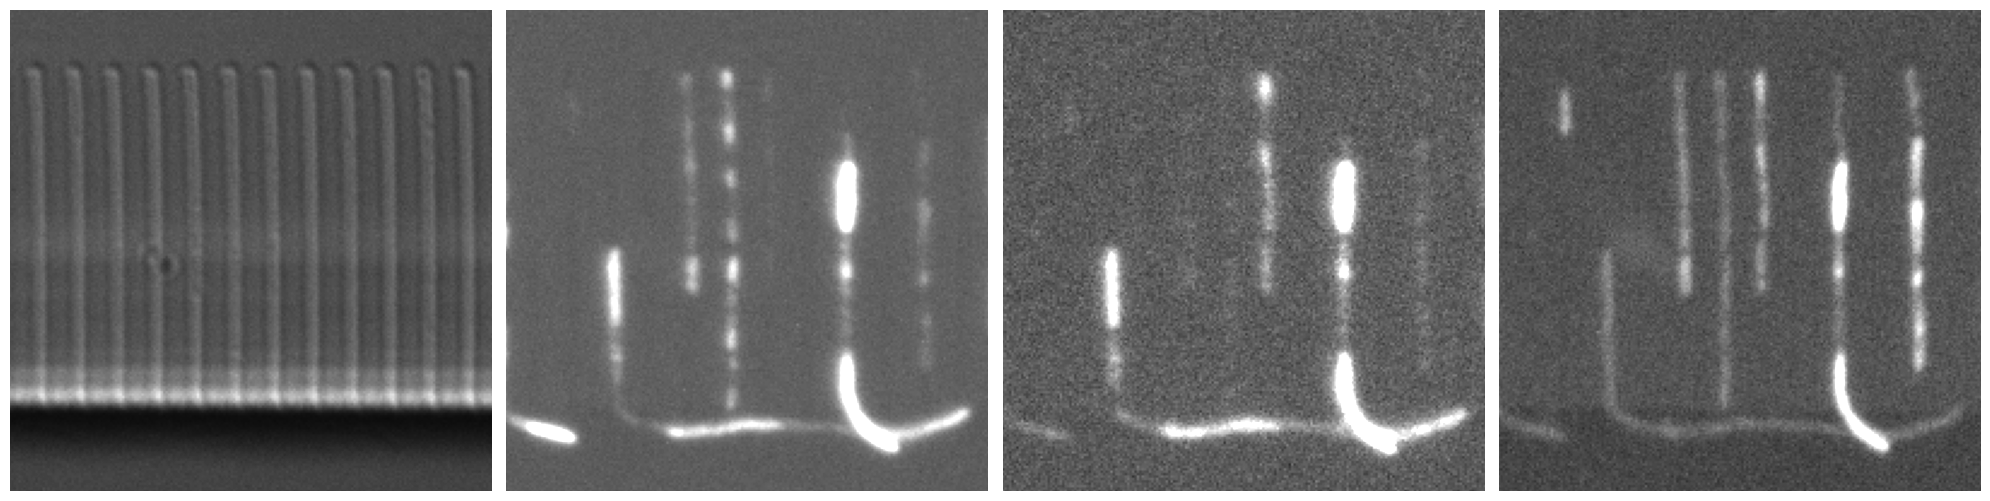

In [69]:
interactive_time_slider(filenames_per_fov_all_channels_time_drift_corrected)

In [66]:
filenames_per_fov_all_channels_time_drift_corrected = group_filenames_per_fov_time(
    '/home/lag36/scratch/lag36/2025-07-13_lLAG8-EZRDM-30C-Run-03/' + "/run_drift_corrected/",
    pattern="*fov*",
    n_timepoints=N_TIMEPOINTS
)

# filenames_per_fov_all_channels_time_drift_corrected